In [1]:
import geopandas as gpd

In [2]:
rivers_poly = gpd.read_file("jamuna_polygon.geojson")

C:\Users\aafir\AppData\Local\Programs\Python\Python313\Lib\site-packages\geopandas\array.py:344: UserWarning: Cannot set the CRS, falling back to None. The CRS support requires the 'pyproj' package, but it is not installed or does not import correctly. The functions depending on CRS will raise an error or may produce unexpected results.
  self.crs = crs
C:\Users\aafir\AppData\Local\Programs\Python\Python313\Lib\site-packages\geopandas\geodataframe.py:469: UserWarning: Cannot set the CRS, falling back to None. The CRS support requires the 'pyproj' package, but it is not installed or does not import correctly. The functions depending on CRS will raise an error or may produce unexpected results.
  level.crs = crs


In [3]:
rivers_line = gpd.read_file("jamuna.geojson")

C:\Users\aafir\AppData\Local\Programs\Python\Python313\Lib\site-packages\geopandas\array.py:344: UserWarning: Cannot set the CRS, falling back to None. The CRS support requires the 'pyproj' package, but it is not installed or does not import correctly. The functions depending on CRS will raise an error or may produce unexpected results.
  self.crs = crs
C:\Users\aafir\AppData\Local\Programs\Python\Python313\Lib\site-packages\geopandas\geodataframe.py:469: UserWarning: Cannot set the CRS, falling back to None. The CRS support requires the 'pyproj' package, but it is not installed or does not import correctly. The functions depending on CRS will raise an error or may produce unexpected results.
  level.crs = crs


In [4]:
rivers_poly.head()

,ripcode,rivname,shape_leng,k50,Basin_Code,st_area_sh,st_length_,geometry
0,01,None,0.0,0,None,1.066475e+06,71131.600314,"MULTIPOLYGON (((88.64993 26.49598, 88.65005 26..."


In [5]:
rivers_line.head()

,OBJECTID,rivname,sub_basin,ba_name,length_km,origin,major_trib,st_pt_lat,st_pt_long,st_loc_ste,...,en_loc_sb_,en_loc_vil,lat,long,UID_River,state_al,Confluence,remark,Shape_Leng,geometry
0,101,Jamuna,Brahmaputra Lower,Brahmaputra,40.509591,None,None,26.511132,88.645706,West Bengal,...,Jalpaiguri,Berubari,26.410491,88.707811,929,West Bengal,Panga,Jamuna,40509.591017,"LINESTRING (88.64571 26.51113, 88.64585 26.510..."


In [6]:
rivers_poly.shape

(1, 8)

In [7]:
rivers_line.shape

(1, 27)

In [8]:
rivers_poly.columns

Index(['ripcode', 'rivname', 'shape_leng', 'k50', 'Basin_Code', 'st_area_sh',
       'st_length_', 'geometry'],
      dtype='str')

In [9]:
rivers_line.columns

Index(['OBJECTID', 'rivname', 'sub_basin', 'ba_name', 'length_km', 'origin',
       'major_trib', 'st_pt_lat', 'st_pt_long', 'st_loc_ste', 'st_loc_dst',
       'st_loc_sb_', 'st_loc_vil', 'en_pt_lat', 'en_pt_long', 'en_loc_ste',
       'en_loc_dst', 'en_loc_sb_', 'en_loc_vil', 'lat', 'long', 'UID_River',
       'state_al', 'Confluence', 'remark', 'Shape_Leng', 'geometry'],
      dtype='str')

In [10]:
rivers_poly.geometry.geom_type

0    MultiPolygon
dtype: str

In [11]:
rivers_line.geometry.geom_type

0    LineString
dtype: str

In [12]:
rivers_poly.crs

In [13]:
rivers_line.crs

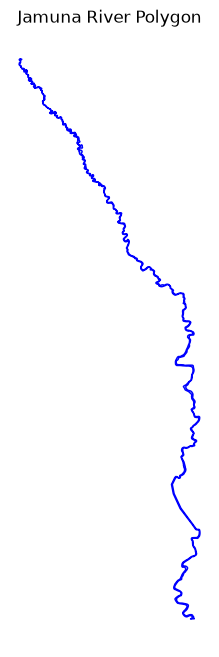

In [14]:
import matplotlib.pyplot as plt

rivers_poly.plot(
    figsize=(10, 8),
    color="lightblue",
    edgecolor="blue"
)

plt.title("Jamuna River Polygon")
plt.axis("off")
plt.show()

In [15]:
rivers_poly["Area_m2"] = rivers_poly.geometry.area
rivers_poly[["rivname", "Area_m2"]]

,rivname,Area_m2
0,None,0.000104


In [16]:
rivers_poly["Area_km2"] = (
    rivers_poly["Area_m2"] / 1_000_000
)

In [17]:
rivers_poly[
    ["rivname", "Area_m2", "Area_km2"]
]

,rivname,Area_m2,Area_km2
0,None,0.000104,1.038369e-10


In [18]:
rivers_poly[
    ["rivname", "st_area_sh", "Area_m2"]
]

,rivname,st_area_sh,Area_m2
0,None,1.066475e+06,0.000104


In [19]:
rivers_poly["Boundary_m"] = rivers_poly.geometry.length
rivers_poly["Boundary_km"] = (
    rivers_poly["Boundary_m"] / 1000
)
rivers_poly[
    ["rivname", "Boundary_m", "Boundary_km"]
]

,rivname,Boundary_m,Boundary_km
0,None,0.717449,0.000717


In [20]:
rivers_line["Length_m"] = rivers_line.geometry.length

rivers_line["Length_km_calculated"] = (
    rivers_line["Length_m"] / 1000
)

rivers_line[
    ["rivname", "Length_m", "Length_km_calculated"]
]

,rivname,Length_m,Length_km_calculated
0,Jamuna,0.390806,0.000391


In [21]:
start_point = rivers_line.geometry.iloc[0].coords[0]
end_point = rivers_line.geometry.iloc[0].coords[-1]

print("Start point:", start_point)
print("End point:", end_point)

Start point: (88.64570596625128, 26.511132338382097)
End point: (88.71643496152953, 26.280886905191014)


In [22]:
straight_distance_m = (
    rivers_line.geometry.iloc[0].coords[0]
)

In [23]:
from shapely.geometry import Point

start = Point(start_point)
end = Point(end_point)

In [24]:
from shapely.geometry import Point

start = Point(rivers_line.geometry.iloc[0].coords[0])
end = Point(rivers_line.geometry.iloc[0].coords[-1])

straight_distance_m = start.distance(end)
straight_distance_km = straight_distance_m / 1000

straight_distance_km

0.00024086417392053022

In [25]:
actual_length_km = rivers_line.geometry.length.iloc[0] / 1000

sinuosity = actual_length_km / straight_distance_km

sinuosity

np.float64(1.62251705972252)

In [26]:
rivers_poly["Centroid"] = rivers_poly.geometry.centroid

In [27]:
centroid = rivers_poly.geometry.centroid.iloc[0]

centroid.x, centroid.y

(88.70129236711269, 26.383560770871078)

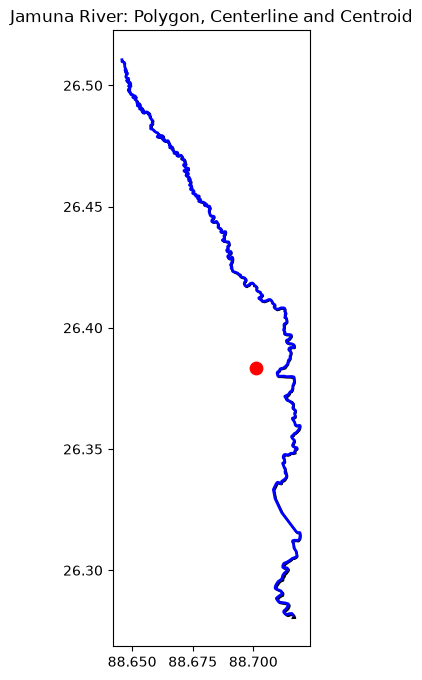

In [28]:
fig, ax = plt.subplots(figsize=(10, 8))

rivers_poly.plot(
    ax=ax,
    color="lightblue",
    edgecolor="black"
)

rivers_line.plot(
    ax=ax,
    color="blue",
    linewidth=2
)

gpd.GeoSeries(
    [centroid],
    crs=rivers_poly.crs
).plot(
    ax=ax,
    color="red",
    markersize=80
)

plt.title("Jamuna River: Polygon, Centerline and Centroid")
plt.show()

In [29]:
rivers_line[
    [
        "rivname",
        "sub_basin",
        "ba_name",
        "length_km",
        "state_al",
        "Confluence"
    ]
]

,rivname,sub_basin,ba_name,length_km,state_al,Confluence
0,Jamuna,Brahmaputra Lower,Brahmaputra,40.509591,West Bengal,Panga


In [30]:
river_length_km = (
    rivers_line.geometry.length.iloc[0] / 1000
)

river_area_km2 = (
    rivers_poly.geometry.area.iloc[0] / 1_000_000
)

boundary_km = (
    rivers_poly.geometry.length.iloc[0] / 1000
)

In [31]:
print("========== JAMUNA RIVER GEOMETRY ANALYSIS ==========")

print(f"Mapped line length     : {river_length_km:.2f} km")
print(f"Straight-line distance : {straight_distance_km:.2f} km")
print(f"Sinuosity              : {sinuosity:.2f}")
print(f"Polygon area           : {river_area_km2:.2f} km²")
print(f"Polygon boundary       : {boundary_km:.2f} km")

========== JAMUNA RIVER GEOMETRY ANALYSIS ==========
Mapped line length     : 0.00 km
Straight-line distance : 0.00 km
Sinuosity              : 1.62
Polygon area           : 0.00 km²
Polygon boundary       : 0.00 km


In [32]:
print("========== JAMUNA RIVER GEOMETRY ANALYSIS ==========")

print(f"Mapped line length     : {river_length_km:.2f} km")
print(f"Straight-line distance : {straight_distance_km:.2f} km")
print(f"Sinuosity              : {sinuosity:.2f}")
print(f"Polygon area           : {river_area_km2:.2f} km²")
print(f"Polygon boundary       : {boundary_km:.2f} km")

========== JAMUNA RIVER GEOMETRY ANALYSIS ==========
Mapped line length     : 0.00 km
Straight-line distance : 0.00 km
Sinuosity              : 1.62
Polygon area           : 0.00 km²
Polygon boundary       : 0.00 km


In [1]:
rivers_ply.total_bounds

NameError: name 'rivers_ply' is not defined

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

rivers_poly = gpd.read_file("jamuna_polygon.geojson")
rivers_line = gpd.read_file("jamuna.geojson")

rivers_poly.crs
rivers_line.crs